<a href="https://colab.research.google.com/github/YASHAS-KING/BIS_LAB/blob/main/BIS_LAB_3_PSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Executing Particle Swarm Optimization on Device: cpu

De Jong Function
Best Position : [-9.4379175e-08 -1.6291290e-07]
Best Fitness  : 0.00000000
Execution Time: 0.024509 seconds

Rastrigin Function
Best Position : [-1.8384835e-06  2.6950060e-05]
Best Fitness  : 0.00000000
Execution Time: 0.016383 seconds

Banana Function
Best Position : [1.0000566 1.0001235]
Best Fitness  : 0.00000001
Execution Time: 0.026134 seconds


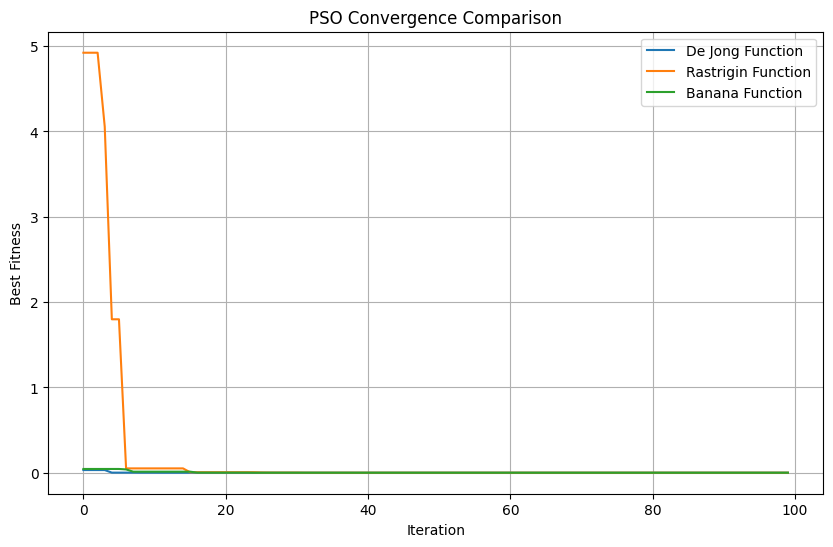

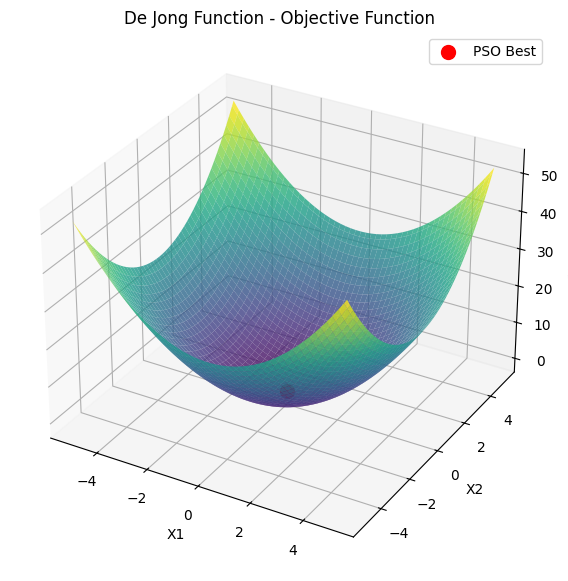

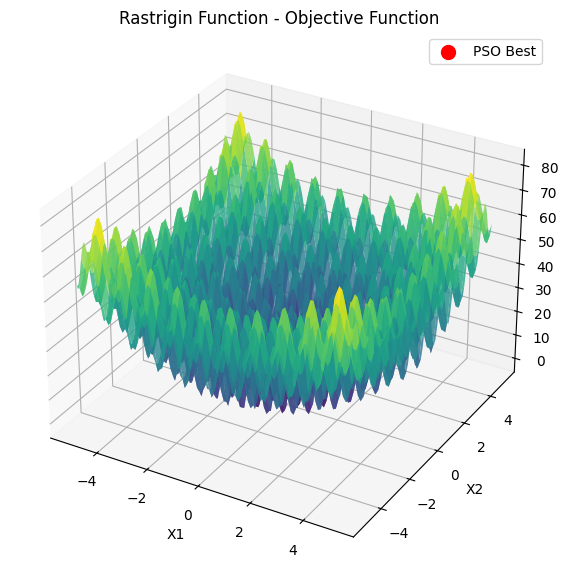

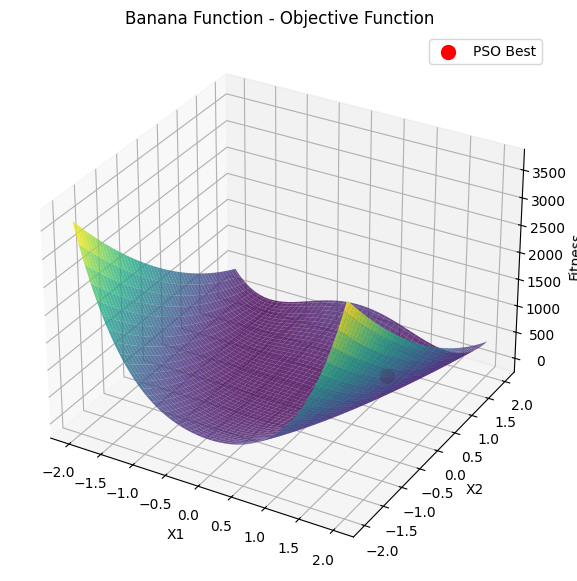

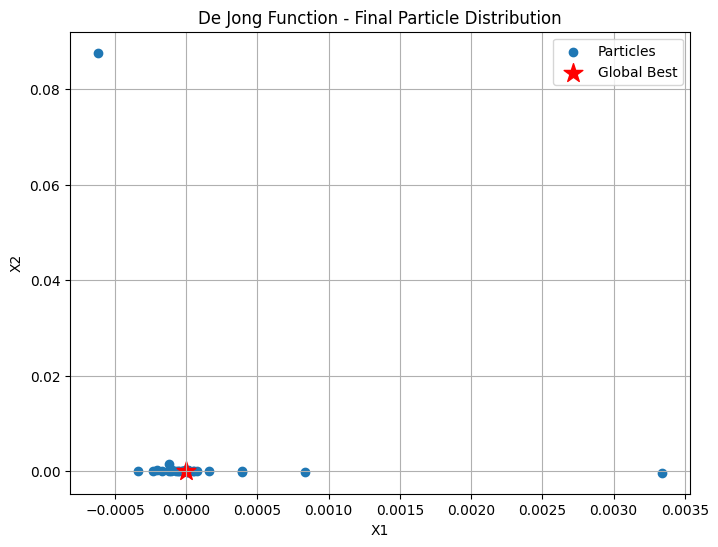

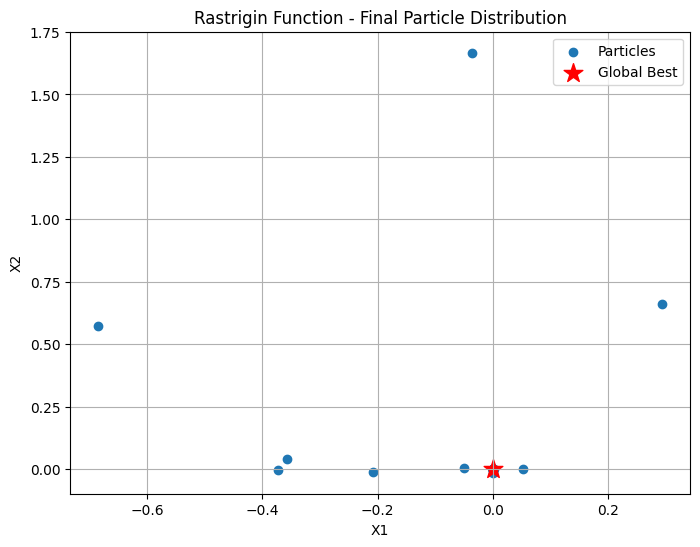

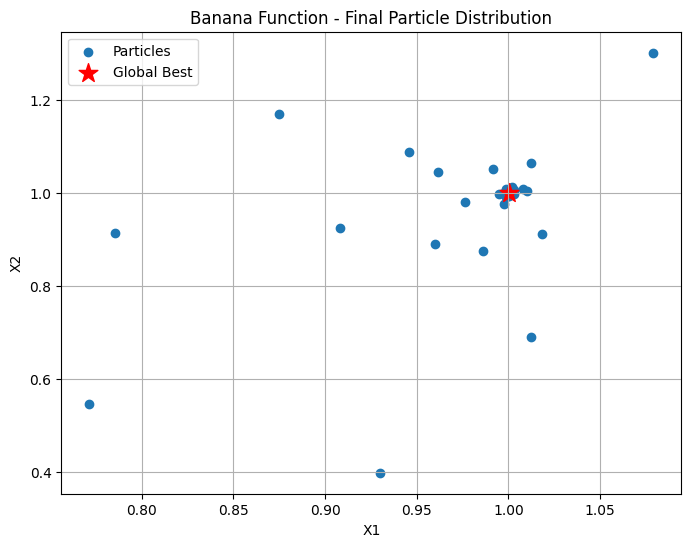


FINAL PSO RESULTS

De Jong Function
Best Position  : [-9.4379175e-08 -1.6291290e-07]
Best Fitness   : 0.00000000
Execution Time : 0.024509 seconds

Rastrigin Function
Best Position  : [-1.8384835e-06  2.6950060e-05]
Best Fitness   : 0.00000000
Execution Time : 0.016383 seconds

Banana Function
Best Position  : [1.0000566 1.0001235]
Best Fitness   : 0.00000001
Execution Time : 0.026134 seconds


In [ ]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ==============================================================================
# DEVICE CONFIGURATION
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing Particle Swarm Optimization on Device: {device}")


# ==============================================================================
# STEP 1: DEFINE OBJECTIVE FUNCTIONS
# ==============================================================================

def de_jong_function(x):
    return torch.sum(x ** 2, dim=1)


def rastrigin_function(x):
    d = x.shape[1]
    return 10 * d + torch.sum(
        x ** 2 - 10 * torch.cos(2 * np.pi * x),
        dim=1
    )


def banana_function(x):
    return torch.sum(
        100 * (x[:, 1:] - x[:, :-1] ** 2) ** 2
        + (1 - x[:, :-1]) ** 2,
        dim=1
    )


# ==============================================================================
# STEP 2: PARTICLE SWARM OPTIMIZATION
# ==============================================================================

class ParticleSwarmOptimization:

    def __init__(
        self,
        objective_function,
        dim=2,
        bounds=(-5.12, 5.12),
        num_particles=50,
        max_iter=100,
        w=0.7,
        c1=1.5,
        c2=1.5
    ):

        self.objective_function = objective_function
        self.dim = dim
        self.lower = bounds[0]
        self.upper = bounds[1]
        self.num_particles = num_particles
        self.max_iter = max_iter

        self.w = w
        self.c1 = c1
        self.c2 = c2

        # Initialize particle positions
        self.X = (
            torch.rand(
                num_particles,
                dim,
                device=device
            ) * (self.upper - self.lower)
            + self.lower
        )

        # Initialize velocities
        self.V = torch.rand(
            num_particles,
            dim,
            device=device
        ) * 2 - 1

        # Initial fitness
        fitness = self.objective_function(self.X)

        # Personal best
        self.pbest_X = self.X.clone()
        self.pbest_fitness = fitness.clone()

        # Global best
        best_index = torch.argmin(self.pbest_fitness)

        self.gbest_X = self.pbest_X[best_index].clone()
        self.gbest_fitness = self.pbest_fitness[best_index].item()

        # History
        self.history = []
        self.position_history = []

    # --------------------------------------------------------------------------
    # OPTIMIZATION
    # --------------------------------------------------------------------------

    def optimize(self):

        start_time = time.time()

        for iteration in range(self.max_iter):

            # Random coefficients
            r1 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            r2 = torch.rand(
                self.num_particles,
                self.dim,
                device=device
            )

            # Velocity update
            self.V = (
                self.w * self.V
                + self.c1 * r1 * (self.pbest_X - self.X)
                + self.c2 * r2 * (self.gbest_X - self.X)
            )

            # Position update
            self.X = self.X + self.V

            # Keep particles inside search space
            self.X = torch.clamp(
                self.X,
                self.lower,
                self.upper
            )

            # Evaluate particles
            fitness = self.objective_function(self.X)

            # Update personal best
            improved = fitness < self.pbest_fitness

            self.pbest_X[improved] = self.X[improved]
            self.pbest_fitness[improved] = fitness[improved]

            # Update global best
            best_index = torch.argmin(self.pbest_fitness)

            current_best = self.pbest_fitness[best_index].item()

            if current_best < self.gbest_fitness:
                self.gbest_fitness = current_best
                self.gbest_X = self.pbest_X[best_index].clone()

            # Store history
            self.history.append(self.gbest_fitness)
            self.position_history.append(
                self.X.detach().cpu().numpy().copy()
            )

        execution_time = time.time() - start_time

        return (
            self.gbest_X.detach().cpu().numpy(),
            self.gbest_fitness,
            execution_time
        )


# ==============================================================================
# STEP 3: RUN PSO FOR EACH FUNCTION
# ==============================================================================

functions = {
    "De Jong Function": {
        "function": de_jong_function,
        "bounds": (-5.12, 5.12)
    },

    "Rastrigin Function": {
        "function": rastrigin_function,
        "bounds": (-5.12, 5.12)
    },

    "Banana Function": {
        "function": banana_function,
        "bounds": (-2.0, 2.0)
    }
}


results = {}


for name, settings in functions.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    pso = ParticleSwarmOptimization(
        objective_function=settings["function"],
        dim=2,
        bounds=settings["bounds"],
        num_particles=50,
        max_iter=100,
        w=0.7,
        c1=1.5,
        c2=1.5
    )

    best_position, best_fitness, execution_time = pso.optimize()

    results[name] = {
        "pso": pso,
        "best_position": best_position,
        "best_fitness": best_fitness,
        "execution_time": execution_time
    }

    print(f"Best Position : {best_position}")
    print(f"Best Fitness  : {best_fitness:.8f}")
    print(f"Execution Time: {execution_time:.6f} seconds")


# ==============================================================================
# STEP 4: CONVERGENCE GRAPHS
# ==============================================================================

plt.figure(figsize=(10, 6))

for name, result in results.items():

    plt.plot(
        result["pso"].history,
        label=name
    )

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()


# ==============================================================================
# STEP 5: OBJECTIVE FUNCTION SURFACES
# ==============================================================================

for name, settings in functions.items():

    lower, upper = settings["bounds"]

    x = np.linspace(lower, upper, 100)
    y = np.linspace(lower, upper, 100)

    X, Y = np.meshgrid(x, y)

    points = torch.tensor(
        np.column_stack(
            [X.ravel(), Y.ravel()]
        ),
        dtype=torch.float32,
        device=device
    )

    Z = settings["function"](points)

    Z = Z.detach().cpu().numpy().reshape(X.shape)

    fig = plt.figure(figsize=(10, 7))

    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        X,
        Y,
        Z,
        cmap="viridis",
        alpha=0.8
    )

    best_position = results[name]["best_position"]

    best_point = torch.tensor(
        best_position.reshape(1, 2),
        dtype=torch.float32,
        device=device
    )

    best_z = settings["function"](best_point)
    best_z = best_z.item()

    ax.scatter(
        best_position[0],
        best_position[1],
        best_z,
        color="red",
        s=100,
        label="PSO Best"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("Fitness")

    ax.set_title(f"{name} - Objective Function")

    ax.legend()

    plt.show()


# ==============================================================================
# STEP 6: PARTICLE DISTRIBUTION
# ==============================================================================

for name, result in results.items():

    pso = result["pso"]

    positions = pso.position_history[-1]

    plt.figure(figsize=(8, 6))

    plt.scatter(
        positions[:, 0],
        positions[:, 1],
        label="Particles"
    )

    best = result["best_position"]

    plt.scatter(
        best[0],
        best[1],
        color="red",
        marker="*",
        s=200,
        label="Global Best"
    )

    plt.xlabel("X1")
    plt.ylabel("X2")

    plt.title(
        f"{name} - Final Particle Distribution"
    )

    plt.legend()
    plt.grid(True)

    plt.show()


# ==============================================================================
# STEP 7: FINAL SUMMARY
# ==============================================================================

print("\n" + "=" * 70)
print("FINAL PSO RESULTS")
print("=" * 70)

for name, result in results.items():

    print(f"\n{name}")
    print(f"Best Position  : {result['best_position']}")
    print(f"Best Fitness   : {result['best_fitness']:.8f}")
    print(f"Execution Time : {result['execution_time']:.6f} seconds")
